# Taller 6 · Punto 2: traducción español → inglés con seq2seq

**Procesamiento de Lenguaje Natural · Maestría · Camilo García**

Código: <https://github.com/CamiloGarcia06/maestria-pln/tree/taller-6>
Reporte escrito: [`README.md`](README.md)

**Objetivo.** Con el dataset *Combined Data es-ES* (publicaciones de salud mental en inglés, `statement`, con su
traducción automática al español, `statement_es_es`) entrenar un modelo **seq2seq** que traduzca del **español al
inglés**, y evaluarlo con **BLEU, ROUGE y F1**, implementadas en [`metricas.py`](metricas.py).

El colab traduce en el sentido contrario (inglés → español) con un corpus de frases cortas (Tatoeba). Aquí:
1. Invertimos la dirección: el **codificador** lee español y el **decodificador** escribe inglés.
2. Las publicaciones son largas (mediana de 53 palabras), así que las **partimos en oraciones** y alineamos
   las de cada idioma (§2).
3. Entrenamos el **GRU seq2seq del colab** y un **Transformer** (el siguiente modelo del mismo capítulo del libro)
   y los comparamos con las tres métricas.

## 1. Configuración

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import json, re, string, time
import warnings
# Avisos de Keras que no afectan el resultado: el tf.data ya viene barajado, y las subcapas internas de la
# atención de keras_hub no "usan" la máscara de relleno (la atención sí la recibe y la aplica).
warnings.filterwarnings("ignore", message=".*shuffle=True.*")
warnings.filterwarnings("ignore", message=".*does not support masking.*")
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
import keras_hub
from keras import layers

import metricas

SEMILLA = 42
RUTA_DATOS = Path("datos/combined_data_es-ES.csv.gz")
RESULTADOS = Path("resultados"); RESULTADOS.mkdir(exist_ok=True)
FIGURAS = Path("figuras"); FIGURAS.mkdir(exist_ok=True)
MODELOS = Path("modelos"); MODELOS.mkdir(exist_ok=True)
keras.utils.set_random_seed(SEMILLA)
print("Keras", keras.__version__, "| keras-hub", keras_hub.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1793045010.144123  320352 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793045010.786291  320352 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras 3.15.1 | keras-hub 0.24.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Datos: de publicaciones a pares de oraciones

In [2]:
crudo = pd.read_csv(RUTA_DATOS, index_col=0)
df = crudo.dropna(subset=["statement", "statement_es_es"])
largo_es = df["statement_es_es"].str.split().str.len()
print(f"Publicaciones: {len(crudo):,} | con ambos textos: {len(df):,}")
print(f"Palabras por publicación (español): mediana {largo_es.median():.0f}, p75 {largo_es.quantile(.75):.0f}, "
      f"p90 {largo_es.quantile(.9):.0f}")
print(f"Publicaciones de ≤ 20 palabras en ambos idiomas: "
      f"{((largo_es <= 20) & (df['statement'].str.split().str.len() <= 20)).sum():,}")

Publicaciones: 53,043 | con ambos textos: 52,680
Palabras por publicación (español): mediana 53, p75 120, p90 216


Publicaciones de ≤ 20 palabras en ambos idiomas: 15,475


Un seq2seq con GRU y vocabulario de palabras trabaja bien con oraciones cortas (el colab usa 20 tokens). Quedarse
solo con las publicaciones cortas dejaría ~15 mil pares. En cambio:

1. **Partimos cada publicación en oraciones** (después de `.`, `!` o `?`) en ambos idiomas.
2. Si la publicación tiene **el mismo número de oraciones** en inglés y en español, emparejamos la *i*-ésima con
   la *i*-ésima (la traducción automática casi siempre conserva las oraciones). Si no, la descartamos, porque no
   sabemos qué oración corresponde a cuál.
3. **Filtros**: 2 a 20 palabras por lado; razón de largos entre 0,5 y 2 (descarta pares mal alineados); el
   inglés sin caracteres fuera de ASCII y el español sin caracteres fuera del alfabeto español (quita
   *mojibake* como `ðŸ'` de emojis mal codificados); español distinto del inglés (hay textos que no se
   tradujeron).

In [3]:
CORTE_ORACION = re.compile(r"(?<=[.!?])\s+")
NO_ASCII = re.compile(r"[^\x00-\x7F]")
NO_ESPANOL = re.compile(r"[^\x00-\x7FáéíóúüñÁÉÍÓÚÜÑ¿¡]")

filas, alineadas = [], 0
for publicacion, (en, es) in enumerate(zip(df["statement"], df["statement_es_es"])):
    oraciones_en = [o for o in CORTE_ORACION.split(en.strip()) if o]
    oraciones_es = [o for o in CORTE_ORACION.split(es.strip()) if o]
    if len(oraciones_en) == len(oraciones_es):
        alineadas += 1
        filas += [(publicacion, o_es, o_en) for o_es, o_en in zip(oraciones_es, oraciones_en)]
pares = pd.DataFrame(filas, columns=["publicacion", "es", "en"])
print(f"Publicaciones con el mismo número de oraciones: {alineadas:,} de {len(df):,}")
print(f"Pares de oraciones: {len(pares):,}")

n_es, n_en = pares["es"].str.split().str.len(), pares["en"].str.split().str.len()
filtros = {
    "2 a 20 palabras": n_es.between(2, 20) & n_en.between(2, 20),
    "razón de largos 0,5–2": (n_es / n_en).between(0.5, 2),
    "sin mojibake": ~pares["en"].str.contains(NO_ASCII) & ~pares["es"].str.contains(NO_ESPANOL),
    "traducido (es ≠ en)": pares["es"].str.lower() != pares["en"].str.lower(),
}
queda = pd.Series(True, index=pares.index)
for nombre, mascara in filtros.items():
    queda &= mascara
    print(f"  tras «{nombre}»: {queda.sum():,}")
pares = pares[queda].drop_duplicates(["es", "en"]).reset_index(drop=True)
print(f"Sin duplicados: {len(pares):,}")
pares.sample(8, random_state=SEMILLA)[["es", "en"]]

Publicaciones con el mismo número de oraciones: 29,787 de 52,680
Pares de oraciones: 107,787


  tras «2 a 20 palabras»: 79,962
  tras «razón de largos 0,5–2»: 77,857
  tras «sin mojibake»: 73,912
  tras «traducido (es ≠ en)»: 72,970
Sin duplicados: 71,242


,es,en
67465,Debes poder relajarte y divertirte sin beber.,You must be able to relax and have fun without...
13744,"Incluso mi hermana y yo, y parece que una pele...","Even my sister and me, and it feels like one f..."
54480,El gato está maullando.,the cat is meowing.
59440,"Sí, obviamente soy la única que responde al te...","@schulman Yes, I am obviously the only one at ..."
9544,Mi hermana se suicidó cuando tenía 19 años y e...,My sister killed herself when I was 19 and tha...
66109,Realmente quiero rendirme porque en mi mente n...,I really want to give up because in my mind th...
58070,El principal problema es que tengo mucha grasa...,Main Problem is that I have a lot of fat in my...
48769,Sigo pensando que voy a volverse loco....,I keep thinking I will go crazy....


**División 80 / 10 / 10 por publicación.** Las oraciones de una misma publicación quedan todas en el mismo
conjunto (si no, el modelo vería en entrenamiento el contexto de las oraciones de prueba). Además quitamos de
validación y prueba las oraciones en español que también están en entrenamiento («me siento solo» aparece en
muchas publicaciones), para medir traducción y no memoria.

In [4]:
publicaciones = pares["publicacion"].unique()
np.random.default_rng(SEMILLA).shuffle(publicaciones)
n = len(publicaciones)
conjunto_de = {p: "train" for p in publicaciones[: int(0.8 * n)]}
conjunto_de.update({p: "val" for p in publicaciones[int(0.8 * n) : int(0.9 * n)]})
conjunto_de.update({p: "test" for p in publicaciones[int(0.9 * n) :]})
pares["conjunto"] = pares["publicacion"].map(conjunto_de)

vistas = set(pares.loc[pares["conjunto"] == "train", "es"].str.lower())
repetidas = (pares["conjunto"] != "train") & pares["es"].str.lower().isin(vistas)
print(f"Oraciones de val/test que ya están en train (se quitan): {repetidas.sum():,}")
pares = pares[~repetidas].reset_index(drop=True)

train_pares = pares[pares["conjunto"] == "train"]
val_pares = pares[pares["conjunto"] == "val"]
test_pares = pares[pares["conjunto"] == "test"]
print(f"Entrenamiento: {len(train_pares):,} | validación: {len(val_pares):,} | prueba: {len(test_pares):,}")

Oraciones de val/test que ya están en train (se quitan): 446
Entrenamiento: 57,257 | validación: 6,747 | prueba: 6,792


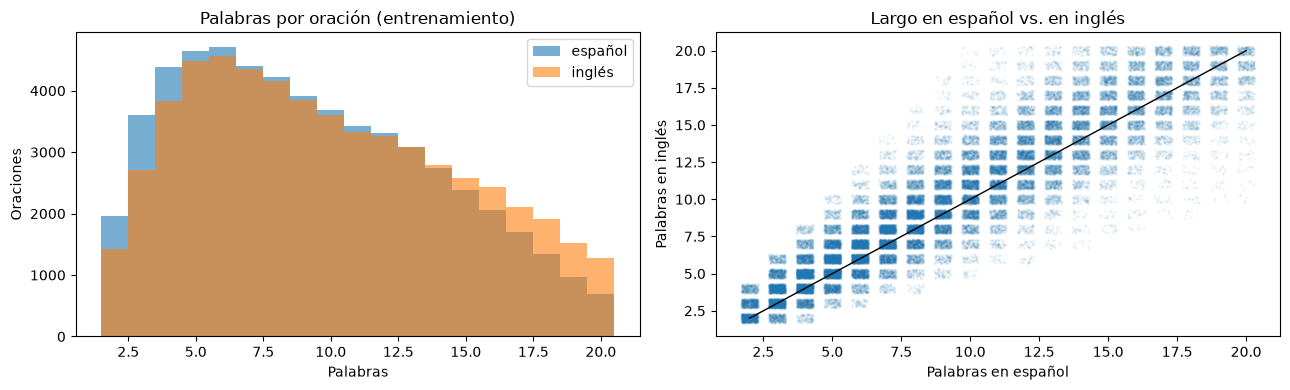

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
largos = pd.DataFrame({"español": train_pares["es"].str.split().str.len(),
                       "inglés": train_pares["en"].str.split().str.len()})
largos.plot.hist(bins=np.arange(1.5, 21.5), alpha=0.6, ax=ejes[0])
ejes[0].set(title="Palabras por oración (entrenamiento)", xlabel="Palabras", ylabel="Oraciones")
ejes[1].scatter(largos["español"] + np.random.uniform(-.3, .3, len(largos)),
                largos["inglés"] + np.random.uniform(-.3, .3, len(largos)), s=1, alpha=0.05)
ejes[1].plot([2, 20], [2, 20], color="black", lw=1)
ejes[1].set(title="Largo en español vs. en inglés", xlabel="Palabras en español", ylabel="Palabras en inglés")
plt.tight_layout(); plt.savefig(FIGURAS / "03_datos_traduccion.png", dpi=120); plt.show()

## 3. Vectorización

Como en el colab, pero con los papeles invertidos: la **fuente** (español) solo se vectoriza; el **objetivo**
(inglés) lleva `[start]` y `[end]`, que el decodificador necesita para saber cuándo empezar y terminar.
Ambos lados se pasan a minúsculas y se les quita la puntuación (incluidos `¿` y `¡`), así que el modelo traduce
texto normalizado y las métricas se calculan sobre ese mismo texto normalizado. Vocabulario de 15.000 palabras
por idioma, ajustado solo con entrenamiento; 20 tokens de fuente y 20 + 1 de objetivo.

In [6]:
TAM_VOCAB = 15000
LARGO = 20
LOTE = 64

quitar = (string.punctuation + "¿¡").replace("[", "").replace("]", "")

def estandarizar(texto):
    return tf.strings.regex_replace(tf.strings.lower(texto), f"[{re.escape(quitar)}]", "")

def normalizar(texto):
    # La misma estandarización en Python puro, para las referencias de las métricas.
    return re.sub(f"[{re.escape(quitar)}]", "", texto.lower()).split()

tok_es = layers.TextVectorization(max_tokens=TAM_VOCAB, output_sequence_length=LARGO, standardize=estandarizar)
tok_en = layers.TextVectorization(max_tokens=TAM_VOCAB, output_sequence_length=LARGO + 1, standardize=estandarizar)
tok_es.adapt(train_pares["es"].tolist())
tok_en.adapt(("[start] " + train_pares["en"] + " [end]").tolist())
vocab_en = tok_en.get_vocabulary()
ID_START, ID_END = vocab_en.index("[start]"), vocab_en.index("[end]")

for nombre, tok, textos in [("español", tok_es, val_pares["es"]), ("inglés", tok_en, val_pares["en"])]:
    ids = tok(textos.tolist()).numpy()
    print(f"Vocabulario {nombre}: {tok.vocabulary_size():,} | tokens desconocidos en validación: "
          f"{(ids == 1).sum() / (ids > 0).sum():.1%}")

Vocabulario español: 15,000 | tokens desconocidos en validación: 4.2%
Vocabulario inglés: 15,000 | tokens desconocidos en validación: 2.8%


In [7]:
def conjunto(df_pares, barajar):
    fuente = tok_es(df_pares["es"].tolist())
    objetivo = tok_en(("[start] " + df_pares["en"] + " [end]").tolist())
    ds = tf.data.Dataset.from_tensor_slices(({"espanol": fuente, "ingles": objetivo[:, :-1]}, objetivo[:, 1:]))
    if barajar:
        ds = ds.shuffle(len(df_pares), seed=SEMILLA)
    # el relleno (id 0) no cuenta en la pérdida
    return ds.batch(LOTE).map(lambda x, y: (x, y, tf.cast(y != 0, "float32"))).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds = conjunto(train_pares, True), conjunto(val_pares, False)
x, y, w = next(iter(train_ds))
print(x["espanol"].shape, x["ingles"].shape, y.shape, w.shape)

(64, 20) (64, 20) (64, 20) (64, 20)


## 4. Modelos

### 4.1 GRU seq2seq (el del colab)

El codificador es un GRU **bidireccional** de 1.024 unidades que resume la oración en español en un vector; ese
vector es el estado inicial del GRU decodificador, que recibe el inglés desplazado un token (*teacher forcing*) y
predice el siguiente. Es exactamente el modelo del colab, con español como fuente.

In [ ]:
def construir_gru(embedding=256, oculto=1024):
    fuente = keras.Input(shape=(None,), dtype="int32", name="espanol")
    x = layers.Embedding(TAM_VOCAB, embedding)(fuente)
    salida_codificador = layers.Bidirectional(layers.GRU(oculto), merge_mode="sum")(x)
    objetivo = keras.Input(shape=(None,), dtype="int32", name="ingles")
    x = layers.Embedding(TAM_VOCAB, embedding)(objetivo)
    x = layers.GRU(oculto, return_sequences=True)(x, initial_state=salida_codificador)
    x = layers.Dropout(0.5)(x)
    predicciones = layers.Dense(TAM_VOCAB, activation="softmax")(x)
    return keras.Model([fuente, objetivo], predicciones, name="gru_seq2seq")

### 4.2 Transformer

El problema del GRU es el **cuello de botella**: toda la oración tiene que caber en un vector de 1.024 números.
El Transformer (Vaswani et al., 2017) deja que el decodificador **atienda** a cada palabra en español en cada paso.
Usamos las capas de `keras_hub` (`TokenAndPositionEmbedding`, `TransformerEncoder`, `TransformerDecoder`) con la
configuración del libro: embeddings de 256, 8 cabezas de atención y capa densa interna de 2.048. El decodificador
aplica máscara causal (no puede mirar palabras futuras) y las máscaras de relleno se propagan desde el embedding.

In [9]:
def construir_transformer(embedding=256, intermedia=2048, cabezas=8):
    fuente = keras.Input(shape=(None,), dtype="int32", name="espanol")
    x = keras_hub.layers.TokenAndPositionEmbedding(TAM_VOCAB, LARGO, embedding, mask_zero=True)(fuente)
    salida_codificador = keras_hub.layers.TransformerEncoder(intermedia, cabezas)(x)
    objetivo = keras.Input(shape=(None,), dtype="int32", name="ingles")
    x = keras_hub.layers.TokenAndPositionEmbedding(TAM_VOCAB, LARGO, embedding, mask_zero=True)(objetivo)
    x = keras_hub.layers.TransformerDecoder(intermedia, cabezas)(x, salida_codificador)
    x = layers.Dropout(0.5)(x)
    predicciones = layers.Dense(TAM_VOCAB, activation="softmax")(x)
    return keras.Model([fuente, objetivo], predicciones, name="transformer")

### 4.3 Entrenamiento

Adam (tasa 1e-3 para el GRU como en el colab; 5e-4 para el Transformer, que es más inestable con tasas altas),
hasta 30 épocas con *early stopping* sobre la pérdida de validación (paciencia 3, se conservan los mejores pesos).

In [10]:
CONFIG = {"gru": (construir_gru, 1e-3), "transformer": (construir_transformer, 5e-4)}
modelos, historias, tiempos = {}, {}, {}
for nombre, (construir, tasa) in CONFIG.items():
    keras.utils.set_random_seed(SEMILLA)
    modelo = construir()
    modelo.compile(optimizer=keras.optimizers.Adam(tasa), loss="sparse_categorical_crossentropy",
                   weighted_metrics=["accuracy"])
    inicio = time.time()
    h = modelo.fit(train_ds, validation_data=val_ds, epochs=30, verbose=0, callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])
    tiempos[nombre] = time.time() - inicio
    modelos[nombre], historias[nombre] = modelo, h.history
    modelo.save(MODELOS / f"traductor_{nombre}.keras")
    mejor = int(np.argmin(h.history["val_loss"]))
    print(f"{nombre:<12} parámetros={modelo.count_params():,} épocas={len(h.history['loss'])} "
          f"mejor={mejor + 1} val_loss={h.history['val_loss'][mejor]:.3f} "
          f"val_acc={h.history['val_accuracy'][mejor]:.3f} ({tiempos[nombre]:.0f} s)")
json.dump(historias, open(RESULTADOS / "traduccion_historias.json", "w"))

gru          parámetros=34,869,912 épocas=9 mejor=6 val_loss=1.662 val_acc=0.486 (533 s)


transformer  parámetros=14,439,064 épocas=7 mejor=4 val_loss=2.249 val_acc=0.585 (130 s)


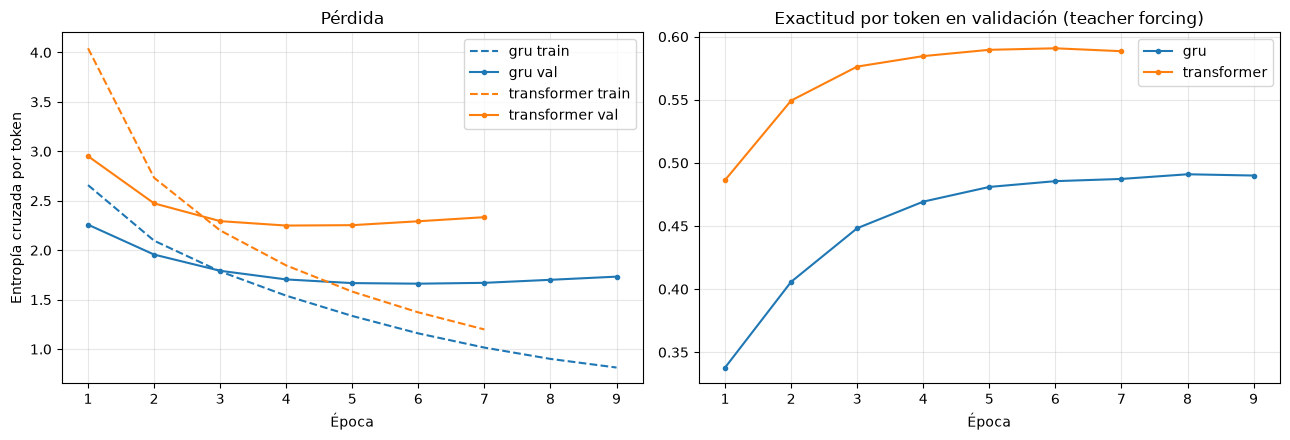

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre, h in historias.items():
    linea, = ejes[0].plot(range(1, len(h["loss"]) + 1), h["loss"], ls="--", label=f"{nombre} train")
    ejes[0].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], marker=".", color=linea.get_color(), label=f"{nombre} val")
    ejes[1].plot(range(1, len(h["val_accuracy"]) + 1), h["val_accuracy"], marker=".", color=linea.get_color(), label=nombre)
ejes[0].set(title="Pérdida", xlabel="Época", ylabel="Entropía cruzada por token")
ejes[1].set(title="Exactitud por token en validación (teacher forcing)", xlabel="Época")
for eje in ejes:
    eje.grid(alpha=0.3); eje.legend()
plt.tight_layout(); plt.savefig(FIGURAS / "04_curvas_traduccion.png", dpi=120); plt.show()

**Ojo con comparar las pérdidas entre modelos.** La `val_loss` de Keras no se calcula igual en los dos:
el Transformer propaga la máscara de relleno hasta la salida y el GRU no, así que Keras las normaliza
distinto (en el GRU, las posiciones de relleno, con peso 0, cuentan en el denominador y bajan el promedio).
Para compararlos calculamos a mano la entropía cruzada **por token real**, igual para los dos:

In [12]:
def entropia_por_token(modelo, ds):
    suma = tokens = 0.0
    for x, y, w in ds:
        probs = np.asarray(modelo.predict_on_batch(x))
        p_correcta = np.take_along_axis(probs, np.asarray(y)[..., None], axis=-1)[..., 0]
        suma += float((-np.log(p_correcta + 1e-9) * np.asarray(w)).sum()); tokens += float(np.asarray(w).sum())
    return suma / tokens

for nombre, modelo in modelos.items():
    print(f"{nombre:<12} entropía cruzada por token real en validación: {entropia_por_token(modelo, val_ds):.3f} "
          f"(val_loss reportada por Keras: {min(historias[nombre]['val_loss']):.3f})")

gru          entropía cruzada por token real en validación: 2.987 (val_loss reportada por Keras: 1.662)


transformer  entropía cruzada por token real en validación: 2.444 (val_loss reportada por Keras: 2.249)


Medida igual para los dos, el **Transformer tiene menor entropía cruzada** (2,44 contra 2,99 nats por token) y mayor
exactitud: es mejor en las dos medidas. La `val_loss` de Keras sirve para la parada temprana de cada modelo, no
para compararlos.

## 5. Traducir

La exactitud por token del entrenamiento usa *teacher forcing*: al predecir la palabra *t* el modelo recibe las
palabras correctas anteriores. Al traducir de verdad no las tiene, así que decodificamos **token por token**:
empezamos con `[start]`, tomamos la palabra más probable (*greedy*, como el colab), la agregamos a la entrada del
decodificador y repetimos hasta `[end]` o 20 tokens. Hacemos lo mismo que `generate_translation` del colab pero
para un lote de oraciones a la vez y trabajando con los índices directamente.

In [13]:
def traducir(modelo, textos_es, lote=512):
    traducciones = []
    for i in range(0, len(textos_es), lote):
        fuente = tok_es(list(textos_es[i : i + lote]))
        decodificado = np.zeros((fuente.shape[0], LARGO), dtype="int32")
        decodificado[:, 0] = ID_START
        terminado = np.zeros(fuente.shape[0], dtype=bool)
        salida = [[] for _ in range(fuente.shape[0])]
        for t in range(LARGO):
            siguiente = np.asarray(modelo.predict_on_batch([fuente, decodificado]))[:, t].argmax(axis=-1)
            for j, token in enumerate(siguiente):
                if not terminado[j]:
                    if token == ID_END:
                        terminado[j] = True
                    else:
                        salida[j].append(vocab_en[token])
            if terminado.all():
                break
            if t + 1 < LARGO:
                decodificado[:, t + 1] = siguiente
        traducciones += salida
    return traducciones

ejemplos = ["me siento muy solo y no sé qué hacer",
            "no he dormido bien en toda la semana",
            "mi familia no entiende lo que estoy pasando",
            "hoy fue un buen día, salí a caminar con mis amigos"]
for nombre, modelo in modelos.items():
    print(f"--- {nombre}")
    for es, en in zip(ejemplos, traducir(modelo, ejemplos)):
        print(f"{es}\n  → {' '.join(en)}")

--- gru
me siento muy solo y no sé qué hacer
  → i feel so alone and i do not know what to do
no he dormido bien en toda la semana
  → i have not eaten at all the past week
mi familia no entiende lo que estoy pasando
  → my family is not doing anything i am going through
hoy fue un buen día, salí a caminar con mis amigos
  → today was a good day i was getting better with my parents
--- transformer


me siento muy solo y no sé qué hacer
  → i feel so lonely and i do not know what to do
no he dormido bien en toda la semana
  → i have not asleep well in the week
mi familia no entiende lo que estoy pasando
  → my family does not understand what i am happening
hoy fue un buen día, salí a caminar con mis amigos
  → today it was a good day i got to walk with my friends


## 6. Métricas

Las tres están implementadas desde cero en [`metricas.py`](metricas.py), sobre tokens normalizados:

- **BLEU** (Papineni et al., 2002), de corpus: precisión de n-gramas (n = 1..4) recortada —una palabra de la
  traducción solo cuenta como acierto tantas veces como aparece en la referencia—, media geométrica de las cuatro
  precisiones y **penalización por brevedad** si las traducciones son más cortas que las referencias. Mide
  *precisión*: cuánto de lo que dijo el modelo está en la referencia, y premia el orden (los 3- y 4-gramas).
- **ROUGE** (Lin, 2004), por oración y promediada: **ROUGE-1** y **ROUGE-2** (traslape de unigramas y bigramas) y
  **ROUGE-L** (subsecuencia común más larga, que respeta el orden sin exigir palabras contiguas). Reportamos la
  medida F (equilibra precisión y *recall*).
- **F1 de tokens** (como en SQuAD), por oración y promediada: precisión y *recall* de la bolsa de palabras, sin
  importar el orden. Responde «¿usó las palabras correctas?».

**Comprobación.** Antes de usarlas, las comparamos con las implementaciones de referencia `sacrebleu` y
`rouge-score` sobre las traducciones del GRU en validación.

In [14]:
import sacrebleu
from rouge_score import rouge_scorer

hip_val = traducir(modelos["gru"], val_pares["es"].tolist())
ref_val = [normalizar(t) for t in val_pares["en"]]
nuestras = metricas.evaluar(hip_val, ref_val)

bleu_ref = sacrebleu.corpus_bleu([" ".join(h) for h in hip_val], [[" ".join(r) for r in ref_val]],
                                 tokenize="none", force=True).score
calificador = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"])
rouge_ref = {k: 100 * np.mean([calificador.score(" ".join(r), " ".join(h))[k].fmeasure
                               for h, r in zip(hip_val, ref_val)]) for k in ("rouge1", "rouge2", "rougeL")}
comprobacion = pd.DataFrame({"metricas.py": nuestras,
                             "librería": {"bleu": bleu_ref, **rouge_ref, "f1": np.nan}}).round(3)
comprobacion

,metricas.py,librería
bleu,16.122,16.122
rouge1,45.833,45.832
rouge2,23.396,23.395
rougeL,43.752,43.751
f1,45.833,NaN


Coinciden (las diferencias en el tercer decimal son de redondeo). **F1 de tokens y ROUGE-1 dan exactamente lo
mismo**, y no es un error: ROUGE-1 cuenta los unigramas comunes recortados (el mínimo de los conteos), que es la
misma intersección de bolsas de palabras que usa el F1 de tokens, y su medida F es la misma media armónica de
precisión y *recall*. Reportamos las dos porque el taller las pide, pero son una sola medida.

## 7. Evaluación en prueba

Además de los dos modelos incluimos una **línea base trivial**: «traducir» copiando la oración en español tal
cual. Sirve para leer las métricas: cualquier puntaje del modelo debe estar muy por encima de esta base (algunas
palabras como nombres, números o «no» coinciden entre idiomas).

In [15]:
ref_test = [normalizar(t) for t in test_pares["en"]]
hipotesis = {"copiar el español": [normalizar(t) for t in test_pares["es"]]}
for nombre, modelo in modelos.items():
    inicio = time.time()
    hipotesis[nombre] = traducir(modelo, test_pares["es"].tolist())
    print(f"{nombre}: {len(test_pares):,} oraciones traducidas en {time.time() - inicio:.0f} s")

resultados = pd.DataFrame({nombre: metricas.evaluar(h, ref_test) for nombre, h in hipotesis.items()}).T
resultados["largo_medio"] = [np.mean([len(x) for x in h]) for h in hipotesis.values()]
resultados.loc["referencia", "largo_medio"] = np.mean([len(r) for r in ref_test])
resultados.to_csv(RESULTADOS / "traduccion_test.csv")
resultados.round(2)

gru: 6,792 oraciones traducidas en 54 s


transformer: 6,792 oraciones traducidas en 55 s


,bleu,rouge1,rouge2,rougeL,f1,largo_medio
copiar el español,0.62,4.30,0.67,4.27,4.30,9.44
gru,15.70,45.11,22.79,43.03,45.11,10.37
transformer,28.72,58.19,35.58,56.45,58.19,9.83
referencia,NaN,NaN,NaN,NaN,NaN,10.06


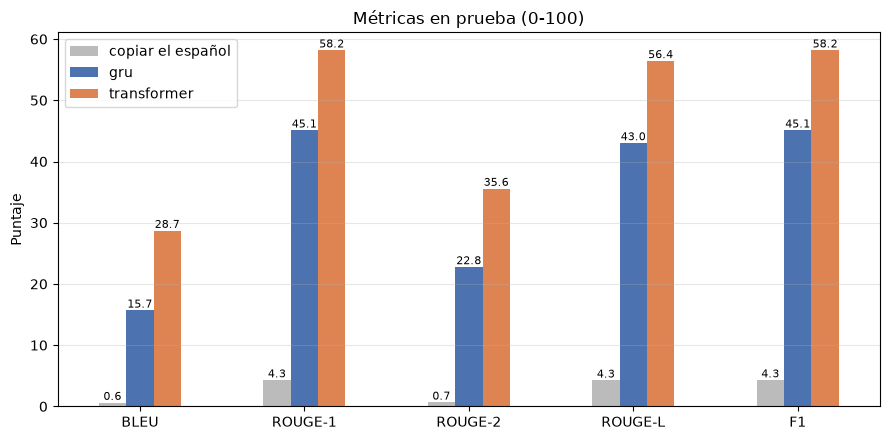

In [16]:
etiquetas = {"bleu": "BLEU", "rouge1": "ROUGE-1", "rouge2": "ROUGE-2", "rougeL": "ROUGE-L", "f1": "F1"}
tabla = resultados.drop(index="referencia")[list(etiquetas)].rename(columns=etiquetas)
eje = tabla.T.plot.bar(figsize=(9, 4.5), rot=0, color=["#BBBBBB", "#4C72B0", "#DD8452"])
for contenedor in eje.containers:
    eje.bar_label(contenedor, fmt="%.1f", fontsize=8)
eje.set(title="Métricas en prueba (0-100)", ylabel="Puntaje"); eje.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(FIGURAS / "05_metricas_test.png", dpi=120); plt.show()

### 7.1 ¿Dónde falla? Desempeño según el largo de la oración

El cuello de botella del GRU predice que su calidad cae más rápido que la del Transformer cuando la oración crece.

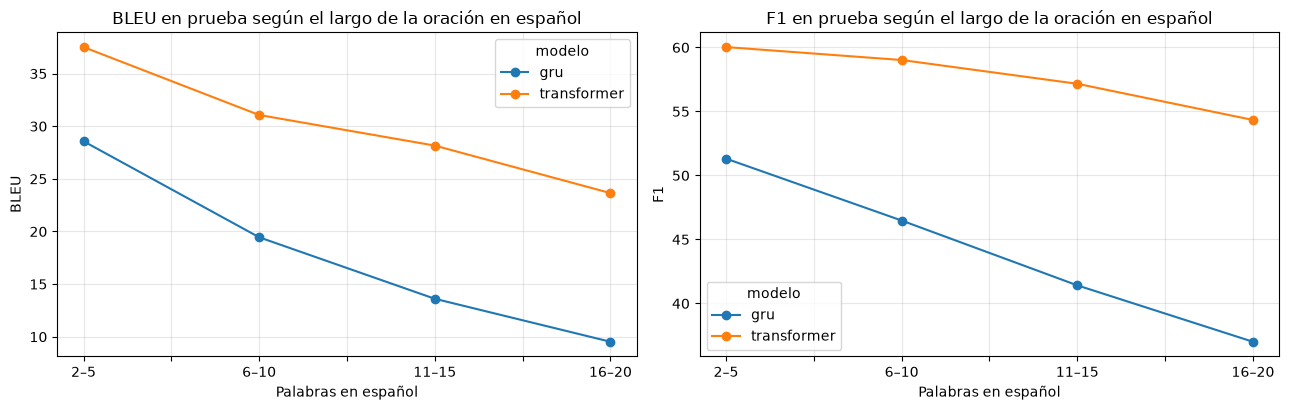

oraciones              bleu                f1            
modelo         gru transformer   gru transformer   gru transformer
palabras                                                          
2–5         1621.0      1621.0  28.6        37.5  51.3        60.0
6–10        2510.0      2510.0  19.5        31.1  46.5        59.0
11–15       1839.0      1839.0  13.6        28.2  41.4        57.2
16–20        822.0       822.0   9.5        23.6  37.0        54.3

In [17]:
largo_fuente = test_pares["es"].str.split().str.len().to_numpy()
tramos = pd.cut(largo_fuente, [1, 5, 10, 15, 20], labels=["2–5", "6–10", "11–15", "16–20"])
filas = []
for tramo in tramos.categories:
    indices = np.flatnonzero(tramos == tramo)
    for nombre in modelos:
        m = metricas.evaluar([hipotesis[nombre][i] for i in indices], [ref_test[i] for i in indices])
        filas.append({"palabras": tramo, "modelo": nombre, "oraciones": len(indices), **m})
por_largo = pd.DataFrame(filas)
por_largo["palabras"] = pd.Categorical(por_largo["palabras"], categories=tramos.categories, ordered=True)
por_largo.to_csv(RESULTADOS / "traduccion_por_largo.csv", index=False)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
for metrica, eje in zip(["bleu", "f1"], ejes):
    por_largo.pivot(index="palabras", columns="modelo", values=metrica).plot(marker="o", ax=eje)
    eje.set(title=f"{etiquetas[metrica]} en prueba según el largo de la oración en español",
            xlabel="Palabras en español", ylabel=etiquetas[metrica]); eje.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIGURAS / "06_por_largo.png", dpi=120); plt.show()
por_largo.pivot(index="palabras", columns="modelo", values=["oraciones", "bleu", "f1"]).round(1)

### 7.2 Ejemplos

Oraciones de prueba al azar con las dos traducciones y su F1 de tokens.

In [18]:
muestra = test_pares.assign(i=range(len(test_pares))).sample(12, random_state=SEMILLA)
filas = []
for _, fila in muestra.iterrows():
    r = ref_test[fila["i"]]
    filas.append({"español": fila["es"], "referencia": " ".join(r),
                  **{f"{m}": " ".join(hipotesis[m][fila["i"]]) for m in modelos},
                  **{f"F1 {m}": round(100 * metricas.f1_tokens(hipotesis[m][fila["i"]], r)[2]) for m in modelos}})
ejemplos_test = pd.DataFrame(filas)
ejemplos_test.to_csv(RESULTADOS / "traduccion_ejemplos.csv", index=False)
pd.set_option("display.max_colwidth", 90)
ejemplos_test

,español,referencia,gru,transformer,F1 gru,F1 transformer
0,Pero él a veces se estrangula y ...,but he sometimes strangles himself and,but he ignored it and sometimes,but he is sometimes he [UNK],67,50
1,"Todo esto es, de alguna manera, peor que el sofocamiento de 2017 (que incluyó varios i...",this whole thing is somehow worse than the 2017 ordeal,everything is like this is going to be the worst [UNK] ever thought about suicide atte...,all this is some way worse than the same as i was [UNK] to several attempts,23,38
2,¿Qué tienen en común Chidambaram y George Bush?,what is common between chidambaram and george bush,what have you done in [UNK] and [UNK],what are you in common and [UNK],25,40
3,"Siento bajone.""",feeling low,i feel [UNK],i feel [UNK],0,0
4,"Él dijo que él también quería besarme, pero teníamos que esperar al momento adecuado.",he said he wanted to kiss me too but we should wait for the right time,he said he wanted to kill him but he was looking at the best way to come out,he said he told him i also wanted to be in the right now,41,47
5,espero que mi nivel de estrés baje cuando mi tía se vaya...,im hoping my stress level will go down when my aunt is gone,i hope my [UNK] [UNK] my [UNK] when the 31st,i hope my [UNK] level of stress when my aunt is going to go,26,59
6,spanx excepto que me perdí la semana pasada de lee y ya se ha ido de iplayer,spanx except i missed last week s lee and now it s gone from iplayer,x200b however i lost all the time i have had a week and it can barely take me,except that i missed out of last week and have been taken out of it,24,47
7,Hoy es mi último día.,today is my last day,today is my last day,today is my last day,100,100
8,¿En quién confío?,what do i trust,where i am done,i am in who i trust,25,40
9,siéntate a mi lado.,come sit next to me,i am going to miss my partner,stressed on my side,17,0
